## Part D: performance incidents, before vs. after

Prints the numbers and saves the figures used in `incident_reports/INC-01.md` … `INC-04.md`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

MACHINE = "luke-mbp16"
# Commit hashes (code_version) measured on the interns' ORIGINAL index code, and on the FIXED code.
# Leave as None to use the earliest and the latest code_version found on MACHINE.
BEFORE = None  
AFTER = None   

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
df = pd.read_csv("../results/timings.csv")
df["ns_per_op"] = df.total_ns / df.n_ops
for c in ["comparisons", "nodes_visited"]:
    df[c + "_per_op"] = df[c] / df.n_ops

exp = df[(df.machine_id == MACHINE) & df.experiment.str.match(r"E[1-6]_")]
order = exp.groupby("code_version").timestamp_utc.min().sort_values()
print("code_versions with E1-E6 rows on", MACHINE)
print(exp.groupby("code_version").experiment.unique().reindex(order.index).to_string())
BEFORE = list(BEFORE or [order.index[0]])
AFTER = [v for v in (AFTER or [order.index[-1]]) if v not in BEFORE]
print(f"\nBEFORE = {BEFORE}   AFTER = {AFTER}")
if not AFTER:
    print("No AFTER rows yet: run the experiments on the fixed commit, then rerun this notebook.")
df["version"] = np.select([df.code_version.isin(BEFORE), df.code_version.isin(AFTER)], ["before", "after"], "other")
exp = df[(df.machine_id == MACHINE) & df.experiment.str.match(r"E[1-6]_") & (df.version != "other")]

def summary(rows, by, cols):
    """Median across replicates for each configuration, BEFORE and AFTER side by side."""
    out = rows.groupby(by + ["version"])[cols].median().unstack("version")
    keep = [(c, v) for c in cols for v in ("before", "after") if (c, v) in out.columns]
    return out[keep].round(1)

def before_after_plot(rows, x, y, label, title, fname, logx=True, refs=()):
    """One line per (index, version); reference indexes drawn dashed in grey."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    colors = {i: f"C{k}" for k, i in enumerate(sorted(rows.index_type.unique()))}
    for (idx, tag), g in rows.groupby(["index_type", "version"]):
        m = g.groupby(x)[y].median()
        if idx in refs:
            if tag != "before": continue   # reference code never changes; draw it once
            ax.plot(m.index, m.values, "--", color="grey", marker=".", label=f"{idx} (reference)")
        else:
            ax.plot(m.index, m.values, "-" if tag == "after" else ":", marker="o",
                    color=colors[idx], label=f"{idx} {tag}")
    if logx: ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(x); ax.set_ylabel(label); ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()
    print("saved analysis/figures/" + fname)

code_versions with E1-E6 rows on luke-mbp16
code_version
65a8adf    [E1_build, E2_point, E3_range, E4_prefix, E5_o...
ccf1a10    [E1_build, E2_point, E3_range, E4_prefix, E5_o...

BEFORE = ['65a8adf']   AFTER = ['ccf1a10']


### INC-01: sorted list point lookup (E2, `track_id`)

comparisons_per_op        ns_per_op        
version                        before after     before   after
index_type  n_keys                                            
ref_bisect  1000                  NaN   NaN      388.9   328.0
            2000                  NaN   NaN      325.7   332.8
            5000                  NaN   NaN      457.2   380.5
            10000                 NaN   NaN      435.7   447.3
            20000                 NaN   NaN      497.4   489.0
            40000                 NaN   NaN      567.2   570.2
            80000                 NaN   NaN      881.4  1165.2
            114000                NaN   NaN     1152.6  1517.9
sorted_list 1000                509.9  10.0    24124.9  1074.2
            2000                993.8  11.0    49552.4  1227.7
            5000               2100.5  12.1   108693.6  1377.5
            10000              4780.3  13.3   260298.8  1596.8
            20000              9329.8  14.2   504102.8  1937.2
            40000             17425.2  15.2   983917.1  1918.8
            80000             33954.4  16.0  2736334.3  2695.2
            114000            46118.9  16.5  3448541.3  3783.2

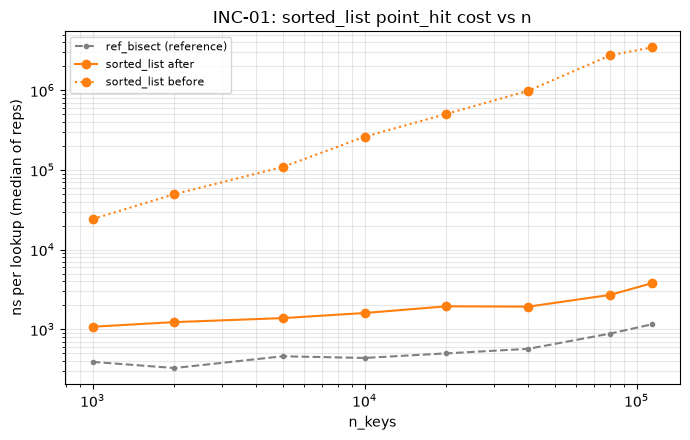

saved analysis/figures/inc01_sorted_list_point.png


In [2]:
r = exp[exp.experiment.str.startswith("E2") & (exp.operation == "point_hit")
        & exp.index_type.isin(["sorted_list", "ref_bisect"])]
display(summary(r, ["index_type", "n_keys"], ["comparisons_per_op", "ns_per_op"]))
before_after_plot(r, "n_keys", "ns_per_op", "ns per lookup (median of reps)",
                  "INC-01: sorted_list point_hit cost vs n", "inc01_sorted_list_point.png",
                  refs=("ref_bisect",))

### INC-02: hash table build (E1, `track_id`)

resizes       ns_per_op        
version            before after    before   after
index_type n_keys                                
hash_table 1000       2.0   8.0     793.0   941.8
           2000       3.0   9.0     815.2   888.2
           5000       6.0  10.0    1027.3   814.6
           10000     13.0  11.0    1858.4   832.6
           20000     25.0  12.0    3694.1   828.5
           40000     47.0  13.0    6067.2   888.2
           80000     87.0  14.0   17048.5  1130.1
           114000   117.0  14.0   27306.6  1076.6
ref_dict   1000       NaN   NaN     228.5   210.2
           2000       NaN   NaN     213.6   179.9
           5000       NaN   NaN     175.7   167.6
           10000      NaN   NaN     171.9   169.4
           20000      NaN   NaN     169.8   160.6
           40000      NaN   NaN     194.2   175.0
           80000      NaN   NaN     209.6   208.0
           114000     NaN   NaN     222.8   231.8

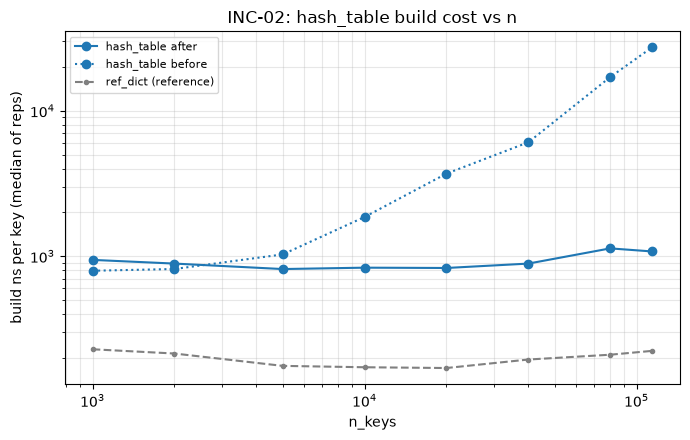

saved analysis/figures/inc02_hash_table_build.png


In [3]:
r = exp[exp.experiment.str.startswith("E1") & (exp.operation == "build")
        & exp.index_type.isin(["hash_table", "ref_dict"])]
display(summary(r, ["index_type", "n_keys"], ["resizes", "ns_per_op"]))
before_after_plot(r, "n_keys", "ns_per_op", "build ns per key (median of reps)",
                  "INC-02: hash_table build cost vs n", "inc02_hash_table_build.png",
                  refs=("ref_dict",))

### INC-03: AVL tree rotations and height (E5, synthetic keys)

rotations_per_insert       height       ns_per_op        
version                            before after before after    before   after
insert_order  n_keys                                                          
nearly_sorted 1000                    6.2   1.1   15.0  12.0    7548.7  5643.8
              10000                   8.2   1.2   21.0  16.0    9441.1  7413.1
              100000                 10.4   1.2   25.0  20.0   12289.8  9415.2
random        1000                    6.6   0.7   14.0  12.0    7877.6  4674.3
              10000                  10.2   0.7   19.0  16.0   12774.7  6345.6
              100000                 14.7   0.7   24.0  20.0   16204.0  7979.6
reversed      1000                    5.9   1.0   14.0  10.0    7070.6  5087.3
              10000                   8.6   1.0   17.0  14.0    8691.5  6617.0
              100000                 11.4   1.0   21.0  17.0   11262.7  8425.4
sorted        1000                    5.9   1.0   14.0  10.0    6921.4  5592.5
              10000                   8.6   1.0   17.0  14.0    9372.0  6992.4
              100000                 11.4   1.0   21.0  17.0   11577.4  8779.3

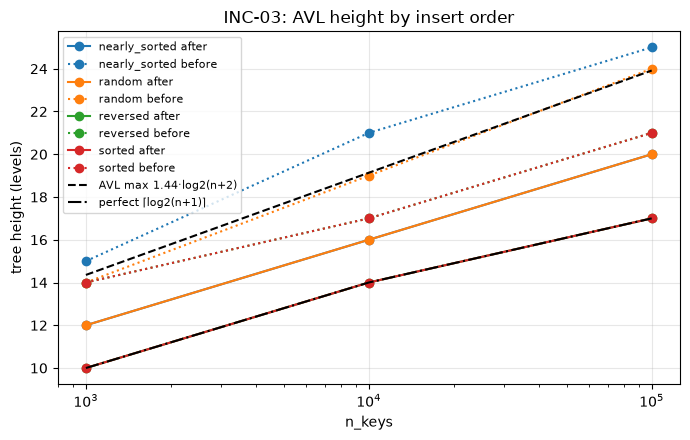

saved analysis/figures/inc03_avl_height.png


In [4]:
r = exp[exp.experiment.str.startswith("E5") & (exp.operation == "build") & (exp.index_type == "avl_tree")].copy()
r["rotations_per_insert"] = r.rotations / r.n_keys
display(summary(r, ["insert_order", "n_keys"], ["rotations_per_insert", "height", "ns_per_op"]))

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {o: f"C{k}" for k, o in enumerate(sorted(r.insert_order.unique()))}
for (o, tag), g in r.groupby(["insert_order", "version"]):
    m = g.groupby("n_keys").height.median()
    ax.plot(m.index, m.values, "-" if tag == "after" else ":", marker="o",
            color=colors[o], label=f"{o} {tag}")
n = np.array(sorted(r.n_keys.unique()))
ax.plot(n, 1.44 * np.log2(n + 2), "k--", label="AVL max 1.44·log2(n+2)")
ax.plot(n, np.ceil(np.log2(n + 1)), "k-.", label="perfect ⌈log2(n+1)⌉")
ax.set_xscale("log"); ax.set_xlabel("n_keys"); ax.set_ylabel("tree height (levels)")
ax.set_title("INC-03: AVL height by insert order"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "inc03_avl_height.png", dpi=150); plt.show()
print("saved analysis/figures/inc03_avl_height.png")

### INC-04: B+ tree range and prefix queries (E3 `tempo`, E4 `track_name`)

comparisons_per_op          nodes_visited_per_op  \
version                                 before    after               before   
index_type  operation_param                                                    
bplus_tree  0.0001                     45653.0     21.9               2197.0   
            0.0010                     45653.0     62.9               2197.0   
            0.0100                     45653.0    473.9               2197.0   
            0.0500                     45653.0   2299.9               2197.0   
            0.1000                     45653.0   4581.8               2197.0   
            0.2500                     45653.0  11429.8               2197.0   
ref_bisect  0.0001                         NaN      NaN                  NaN   
            0.0010                         NaN      NaN                  NaN   
            0.0100                         NaN      NaN                  NaN   
            0.0500                         NaN      NaN                  NaN   
            0.1000                         NaN      NaN                  NaN   
            0.2500                         NaN      NaN                  NaN   
sorted_list 0.0001                        21.5     21.5                  0.0   
            0.0010                        62.5     62.5                  0.0   
            0.0100                       473.5    473.5                  0.0   
            0.0500                      2299.5   2299.5                  0.0   
            0.1000                      4581.6   4581.6                  0.0   
            0.2500                     11429.6  11429.6                  0.0   

                                    ns_per_op             
version                      after     before      after  
index_type  operation_param                               
bplus_tree  0.0001             4.2  3583950.6     4914.4  
            0.0010             6.1  3558424.0    11616.5  
            0.0100            25.0  3559227.5    83536.0  
            0.0500           109.0  3636951.7   387346.5  
            0.1000           214.0  3731998.1   796455.4  
            0.2500           529.0  4020906.3  1880925.0  
ref_bisect  0.0001             NaN     1271.7     1908.8  
            0.0010             NaN     3914.6     5730.4  
            0.0100             NaN    23334.4    27441.9  
            0.0500             NaN   113166.9   112155.4  
            0.1000             NaN   208101.5   208242.9  
            0.2500             NaN   555777.7   513602.5  
sorted_list 0.0001             0.0     3183.3     3073.1  
            0.0010             0.0    13739.4    11630.6  
            0.0100             0.0    92171.5    78716.0  
            0.0500             0.0   387362.9   374012.1  
            0.1000             0.0   731287.9   745009.4  
            0.2500             0.0  1849030.4  1876016.0

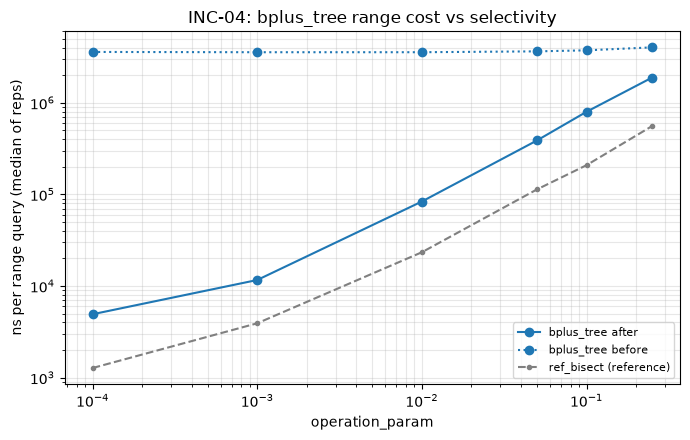

saved analysis/figures/inc04_bplus_range.png


comparisons_per_op          ns_per_op          
version                     before   after     before     after
operation_param                                                
1.0                        72396.0  3661.1  6629666.9  724520.6
2.0                        72396.0   642.9  6484621.0  146504.0
3.0                        72396.0   184.8  8130700.6   42678.5
4.0                        72396.0    92.2  7493774.6   26695.4
5.0                        72396.0    40.4  6315837.7   10313.8

In [5]:
r = exp[exp.experiment.str.startswith("E3") & (exp.operation == "range")
        & exp.index_type.isin(["bplus_tree", "sorted_list", "ref_bisect"])]
display(summary(r, ["index_type", "operation_param"], ["comparisons_per_op", "nodes_visited_per_op", "ns_per_op"]))
before_after_plot(r[r.index_type != "sorted_list"], "operation_param", "ns_per_op",
                  "ns per range query (median of reps)",
                  "INC-04: bplus_tree range cost vs selectivity", "inc04_bplus_range.png",
                  refs=("ref_bisect",))

p = exp[exp.experiment.str.startswith("E4") & (exp.operation == "prefix") & (exp.index_type == "bplus_tree")]
display(summary(p, ["operation_param"], ["comparisons_per_op", "ns_per_op"]))

### Sanity check

In [6]:
core = df[(df.experiment == "CORE") & (df.version == "after") & df.comparisons.notna()]
cols = ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]
spread = core.groupby(["index_type", "operation", "n_keys"])[cols].nunique()
display(spread[(spread > 1).any(axis=1)])

,,,comparisons,nodes_visited,rotations,splits,resizes
index_type,operation,n_keys,,,,,
